# 03 – Décision, coûts et ROI

Ce notebook couvre les axes 6 (justification par les coûts), 7 (ROI) et 9 (risques).

Étapes :
1. vérifier que les probabilités du modèle sont réalistes ;
2. poser les hypothèses de coût ;
3. construire la règle de décision (qui appeler) ;
4. comparer plusieurs seuils sur le test ;
5. calculer le ROI et sa sensibilité aux hypothèses ;
6. contrôler l'équité ;
7. registre des risques ;
8. recommandation.

In [1]:
#imports, même découpage qu'au notebook 02, chargement du modèle, montants en euros et probabilités

import sys

sys.path.append("..")         

import joblib

import numpy as np

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_predict

from src.donnees import preparer_donnees, VARIABLES_MODELE

from src.couts import TAUX_CHANGE, PERTE, EFFICACITE, COUT_APPEL, FACTEUR_ANNUEL, COUT_PROJET, cout_total

sns.set_theme(style="whitegrid")

FIGURES = "../reports/figures/"

# comme dans le notebook 2
df = preparer_donnees()

X = df[VARIABLES_MODELE]

y = df["defaut"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

modele = joblib.load("../models/modele_final.joblib")     


# Montant à risque de chaque client (facture de septembre, 0 si négative), converti en euros

montant_train = df.loc[X_train.index, "facture_sep"].clip(lower=0).values / TAUX_CHANGE

montant_test = df.loc[X_test.index, "facture_sep"].clip(lower=0).values / TAUX_CHANGE

defaut_train = (y_train == 1).values

defaut_test = (y_test == 1).values

proba_train = cross_val_predict(modele, X_train, y_train, cv=5, method="predict_proba")[:, 1]

proba_test = modele.predict_proba(X_test)[:, 1]


def appeler_les_plus_risques(score, part):
    return score >= np.quantile(score, 1 - part)

## 1. Les probabilités sont-elles réalistes ?

Je vais multiplier la probabilité de défaut par le montant de la facture. Il faut donc que la probabilité soit juste : si le modèle annonce 30 %, il faut qu'environ 30 % de ces clients fassent vraiment défaut.

Je le vérifie sur le train, avec les prédictions hors pli : je range les clients en 10 groupes selon leur probabilité, et je compare dans chaque groupe la probabilité moyenne prédite au taux de défaut réel.

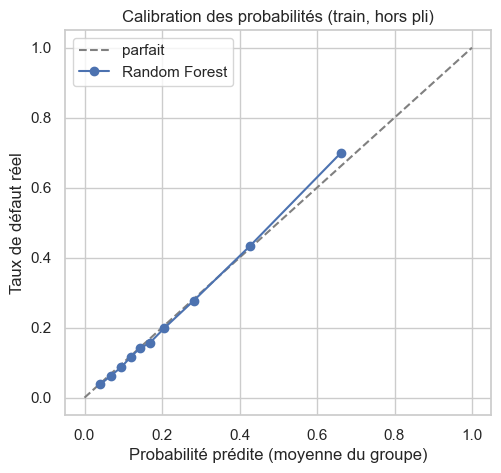

Probabilité moyenne prédite : 0.221 | taux de défaut réel : 0.221


,probabilité prédite,taux de défaut réel
"(0.0116, 0.055]",0.041,0.038
"(0.055, 0.0808]",0.068,0.062
"(0.0808, 0.108]",0.095,0.087
"(0.108, 0.131]",0.120,0.117
"(0.131, 0.154]",0.143,0.141
"(0.154, 0.183]",0.168,0.156
"(0.183, 0.235]",0.206,0.199
"(0.235, 0.341]",0.282,0.278
"(0.341, 0.557]",0.428,0.434
"(0.557, 0.846]",0.662,0.700


In [2]:
groupes = pd.qcut(proba_train, 10)


calibration = pd.DataFrame({"probabilité prédite": proba_train, "taux de défaut réel": defaut_train})

calibration = calibration.groupby(groupes, observed=True).mean()

plt.figure(figsize=(5.5, 5))

plt.plot([0, 1], [0, 1], "--", color="gray", label="parfait")

plt.plot(calibration["probabilité prédite"], calibration["taux de défaut réel"], "o-", label="Random Forest")

plt.xlabel("Probabilité prédite (moyenne du groupe)")

plt.ylabel("Taux de défaut réel")

plt.title("Calibration des probabilités (train, hors pli)")

plt.legend()

plt.savefig(FIGURES + "calibrage.png", dpi=150, bbox_inches="tight")

plt.show()

print("Probabilité moyenne prédite :", round(proba_train.mean(), 3), "| taux de défaut réel :", round(defaut_train.mean(), 3))
calibration.round(3)

#calibration : la probabilité prédite correspond-elle au taux de défaut réel ? on trouvera la reponse dnas la suite

Dans chaque groupe, la probabilité prédite est proche du taux de défaut réel : les points suivent presque la diagonale. La probabilité moyenne prédite (22,1 %) est égale au taux réel. Je peux donc utiliser ces probabilités pour calculer une perte attendue.

## 2. Hypothèses de coût (axe 6)

Je n'ai pas les coûts réels de la banque. Je pose des hypothèses prudentes, toutes regroupées dans `src/couts.py`, et je teste leur effet en partie 5.

| Hypothèse | Valeur | Justification |
|---|---|---|
| Taux de change | 1 € = 40,0 TWD | Moyennes 2005 de la Réserve fédérale (release G.5A) : 1,2449 dollar pour 1 € et 32,131 TWD pour 1 dollar |
| Montant à risque | facture de septembre (0 si négative) | c'est ce que le client doit payer |
| Perte finale si le défaut n'est pas anticipé | 10 % du montant | un défaut est un mois d'impayé : au Royaume-Uni, 61 à 71 % des clients en retard d'un mois régularisent (FICO, 2019) ; une fois la créance passée en perte, la banque n'en récupère que 10 à 15 % (Fed de Philadelphie, 2012). La perte va de quelques % pour un premier retard à bien plus pour un client déjà en retard de 2 mois : 10 % est une valeur moyenne |
| Efficacité d'un appel préventif | évite 10 % de cette perte | les rappels étudiés (SMS, application) réduisent les retards de 4 à 7 % (Campbell et al., 2022 ; expérience en Colombie). Un appel de conseiller est sans doute plus efficace, mais aucune étude ne le chiffre : 10 % est une valeur prudente |
| Coût d'un appel | 10 € | environ 10 minutes de conseiller : une heure de travail en centre d'appels interne coûte 50 à 60 € à une entreprise (AFRC, citée par la Banque des Territoires, 2010) |
| Passage à l'année | × 5 × 12 | le test (6 000 clients) représente 1/5 d'un portefeuille de 30 000 clients, et la décision est prise chaque mois |
| Coût du projet (1re année) | 55 000 € | 30 000 € de développement, soit environ 56 jours de data scientist à 533 € par jour (tarif journalier moyen des freelances « Data » en France, Kicklox 2025) ; 15 000 € d'intégration et 10 000 € d'exploitation (hypothèses) |

Sources : [Réserve fédérale, G.5A, 2006](https://www.federalreserve.gov/Releases/g5a/20060103/G5A.htm) ; [FICO, 2019](https://www.fico.com/blogs/uk-card-delinquency-roll-rates-creep-higher) ; [Fed de Philadelphie, WP 12-18, 2012](https://www.philadelphiafed.org/-/media/FRBP/Assets/working-papers/2012/wp12-18.pdf) ; [Campbell, Grant et Thorp, 2022](https://ideas.repec.org/a/eee/jbfina/v142y2022ics0378426622001431.html) ; [VoxDev, expérience en Colombie](https://www.voxdev.org/topic/finance/how-can-behavioural-messaging-campaigns-be-tailored-reduce-loan-delinquency) ; [Kicklox, étude TJM 2025](https://www.kicklox.com/wp-content/uploads/2025/10/KICKLOX-GROUPE-DIDAXIS-Etude-2025-TJM-freelances-tech_compressed.pdf) ; [Banque des Territoires, 2010](https://www.banquedesterritoires.fr/relocalisation-des-centres-dappels-un-effet-dannonce) ; [Taipei Times, 9 mars 2006](https://www.taipeitimes.com/News/biz/archives/2006/03/09/2003296519).

Contexte : les données datent de 2005, en pleine crise des cartes de crédit à Taïwan. Fin 2005, la part des encours de cartes passée en perte y atteignait 12 à 15 % par an, contre environ 6 % avant la crise (Taipei Times, 2006). Les défauts coûtaient donc sans doute plus cher qu'en temps normal, et c'est une raison de plus pour réentraîner le modèle sur des données récentes avant de l'utiliser (registre des risques, partie 7).

**Matrice de coûts**, pour un client dont le montant à risque est M :

| | Défaut | Pas de défaut |
|---|---|---|
| **Appelé** | coût de l'appel + perte restante : 10 € + 10 % × M × (1 − 10 %) | coût de l'appel : 10 € |
| **Pas appelé** | perte complète : 10 % × M | 0 |

## 3. Règle de décision : qui appeler ?

Appeler un client coûte 10 €. L'appel fait gagner, en moyenne : probabilité de défaut × M × 10 % × 10 %. Un appel est donc rentable si :

**probabilité × M > 10 € / (10 % × 10 %) = 1 000 €**

Le gain d'un appel dépend de la « perte attendue » (probabilité × montant). Je classe donc les clients par perte attendue, et pas seulement par probabilité.

Deux façons de décider combien de clients appeler :
- **garder la capacité actuelle** : appeler autant de clients que la règle (environ 23 %), en commençant par les plus fortes pertes attendues. L'équipe ne change pas, et c'est le critère de succès du cadrage ;
- **appeler seulement si c'est rentable** : perte attendue > 1 000 €. Ce seuil vient directement des hypothèses, il n'est pas réglé sur le jeu de test.

Je regarde d'abord sur le train (prédictions hors pli) comment le coût total varie avec le nombre d'appels.

Appeler si probabilité x montant > 1000 €


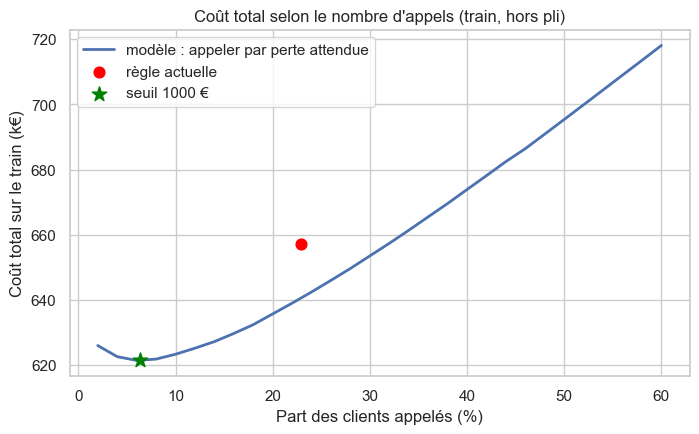

Clients appelés avec ce seuil : 6.4 %
Part de clients appelés au coût minimal : 6 %


In [3]:
SEUIL = COUT_APPEL / (PERTE * EFFICACITE)        

print("Appeler si probabilité x montant >", round(SEUIL), "€")

perte_attendue_train = proba_train * montant_train

regle_train = (X_train["retard_sep"] >= 1).values

parts = np.arange(0.02, 0.62, 0.02)
  # de 2 % à 60 % de clients appelés

couts = []

for part in parts:
    appele = appeler_les_plus_risques(perte_attendue_train, part)
    couts.append(cout_total(appele, defaut_train, montant_train))

appele_seuil = perte_attendue_train > SEUIL

# le seuil de rentabilité (1 000 €) et coût total selon le nombre de clients appelés
plt.figure(figsize=(8, 4.5))

plt.plot(parts * 100, np.array(couts) / 1000, lw=2, label="modèle : appeler par perte attendue")

plt.scatter([regle_train.mean() * 100], [cout_total(regle_train, defaut_train, montant_train) / 1000],
            color="red", s=60, zorder=3, label="règle actuelle")

plt.scatter([appele_seuil.mean() * 100], [cout_total(appele_seuil, defaut_train, montant_train) / 1000],
            color="green", marker="*", s=120, zorder=3, label=f"seuil {SEUIL:.0f} €")

plt.xlabel("Part des clients appelés (%)")

plt.ylabel("Coût total sur le train (k€)")

plt.title("Coût total selon le nombre d'appels (train, hors pli)")

plt.legend()

plt.savefig(FIGURES + "cout selon volume.png", dpi=150, bbox_inches="tight")

plt.show()

print("Clients appelés avec ce seuil :", round(appele_seuil.mean() * 100, 1), "%")

print("Part de clients appelés au coût minimal :", round(parts[np.argmin(couts)] * 100), "%")

Le coût total baisse quand on appelle d'abord les plus fortes pertes attendues, atteint son minimum vers 6 % de clients appelés, puis remonte : au-delà, on appelle des clients dont la perte attendue est trop faible pour payer l'appel. Le seuil de 1 000 € tombe aussi vers 6 % de clients appelés : le calcul et la courbe sont d'accord. Le point rouge (la règle actuelle) est au-dessus de la courbe : à nombre d'appels égal, la règle coûte plus cher que le modèle.

## 4. Comparaison de plusieurs seuils sur le test (axe 6)

J'applique maintenant les politiques au jeu de test, une seule fois. Je compare :
- la règle actuelle ;
- le modèle avec la même capacité d'appels que la règle (politique retenue, critère de succès du cadrage) ;
- le modèle avec trois seuils de perte attendue : 500 €, 1 000 € (seuil de rentabilité) et 2 000 €.

Les coûts sont ceux d'un mois sur les 6 000 clients du test.

In [4]:
perte_attendue_test = proba_test * montant_test
regle_test = (X_test["retard_sep"] >= 1).values

politiques = {
    "Règle actuelle": regle_test,
    "Modèle, même capacité (retenu)": appeler_les_plus_risques(perte_attendue_test, regle_test.mean()),
    "Modèle, seuil 500 €": perte_attendue_test > 500,
    "Modèle, seuil 1 000 € (rentabilité)": perte_attendue_test > SEUIL,
    "Modèle, seuil 2 000 €": perte_attendue_test > 2000,
}
# comparaison des politiques sur le test : regle, même capacité, seuils 500, 1 000 et 2 000 €
lignes = []
for nom, appele in politiques.items():
    trouves = appele & defaut_test
    lignes.append({
        "politique": nom,
        "clients appelés (%)": appele.mean() * 100,
        "défauts trouvés (%)": trouves.sum() / defaut_test.sum() * 100,
        "appels utiles (%)": trouves.sum() / appele.sum() * 100,
        "montants en défaut couverts (%)": montant_test[trouves].sum() / montant_test[defaut_test].sum() * 100,
        "coût total (€)": cout_total(appele, defaut_test, montant_test),
    })
comparaison = pd.DataFrame(lignes).set_index("politique")

comparaison["gain vs règle (€)"] = comparaison.loc["Règle actuelle", "coût total (€)"] - comparaison["coût total (€)"]

comparaison.round(1)

,clients appelés (%),défauts trouvés (%),appels utiles (%),montants en défaut couverts (%),coût total (€),gain vs règle (€)
politique,,,,,,
Règle actuelle,22.1,49.7,49.8,55.3,172090.8,0.0
"Modèle, même capacité (retenu)",22.1,36.4,36.5,80.3,167888.8,4202.0
"Modèle, seuil 500 €",14.6,28.0,42.4,71.5,164896.2,7194.6
"Modèle, seuil 1 000 € (rentabilité)",7.0,16.2,51.2,53.8,163302.5,8788.3
"Modèle, seuil 2 000 €",2.0,5.9,65.5,29.5,164379.3,7711.5


- À capacité égale (22,1 % des clients), le modèle couvre 80,3 % des montants en défaut, contre 55,3 % pour la règle. Autrement dit, sur 100 € qui partent en défaut, le modèle en couvre 80 et la règle 55. Le critère de succès (au moins 70 %) est atteint.
- Le modèle trouve pourtant moins de défauts (36,4 % contre 49,7 %) : il laisse de côté de petits défauts pour appeler les gros montants. C'est voulu, puisque la perte dépend du montant.
- Le coût total baisse de 4 202 € sur le mois de test.
- Avec le seuil de rentabilité (1 000 €), on n'appelle que 7,0 % des clients et on couvre 53,8 % des montants : presque autant que la règle, avec trois fois moins d'appels. C'est la politique la moins chère du tableau : avec nos hypothèses, beaucoup d'appels actuels ne sont pas rentables.
- Le seuil de 500 € couvre plus de montants (71,5 %) mais fait deux fois plus d'appels ; celui de 2 000 € rate trop de montants (29,5 % couverts).

### Matrices de confusion

Avec le même nombre d'appels (22,1 % des clients du test), je compare trois décisions : la règle actuelle, le modèle trié par probabilité seule (comme au notebook 02) et le modèle retenu, trié par perte attendue. Lignes : la réalité (défaut ou non). Colonnes : la décision (client appelé ou non).

- VP (vrai positif) : défaut appelé ; FP (faux positif) : appel inutile ;
- FN (faux négatif) : défaut non appelé ; VN (vrai négatif) : client sain non appelé.

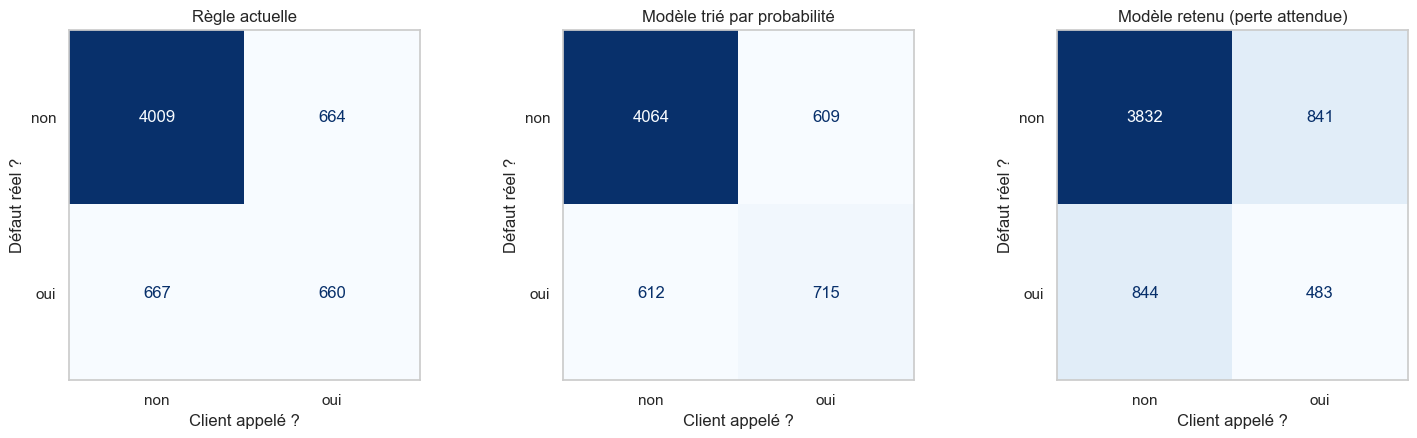

,VP,FP,FN,VN,rappel (%),précision (%),F1 (%),spécificité (%),accuracy (%),montants couverts (%)
décision,,,,,,,,,,
Règle actuelle,660,664,667,4009,49.7,49.8,49.8,85.8,77.8,55.3
Modèle trié par probabilité,715,609,612,4064,53.9,54.0,53.9,87.0,79.6,56.5
Modèle retenu (perte attendue),483,841,844,3832,36.4,36.5,36.4,82.0,71.9,80.3


In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

decisions = {
    "Règle actuelle": regle_test,
    "Modèle trié par probabilité": appeler_les_plus_risques(proba_test, regle_test.mean()),
    "Modèle retenu (perte attendue)": politiques["Modèle, même capacité (retenu)"],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

resume_matrices = []

for ax, (nom, appele) in zip(axes, decisions.items()):
    matrice = confusion_matrix(defaut_test, appele)      
    # lignes : réalité, colonnes : décision
    ConfusionMatrixDisplay(matrice, display_labels=["non", "oui"]).plot(
        ax=ax, colorbar=False, values_format="d", cmap="Blues")
    ax.set_title(nom)
    ax.set_xlabel("Client appelé ?")
    ax.set_ylabel("Défaut réel ?")
    ax.grid(False)

# Matrices de confusion des 3 décisions, à nombre d'appels égal
    vn, fp, fn, vp = matrice.ravel()
    resume_matrices.append({
        "décision": nom, "VP": vp, "FP": fp, "FN": fn, "VN": vn,
        "rappel (%)": vp / (vp + fn) * 100,
        "précision (%)": vp / (vp + fp) * 100,
        "F1 (%)": 2 * vp / (2 * vp + fp + fn) * 100,
        "spécificité (%)": vn / (vn + fp) * 100,
        "accuracy (%)": (vp + vn) / len(defaut_test) * 100,
        "montants couverts (%)": montant_test[appele & defaut_test].sum() / montant_test[defaut_test].sum() * 100,
    })
#pour les matrices

plt.tight_layout()

plt.savefig(FIGURES + "matrice de confusion.png", dpi=150, bbox_inches="tight")

plt.show()

pd.DataFrame(resume_matrices).set_index("décision").round(1)

- La règle actuelle trouve 660 défauts sur 1 327 (rappel de 49,7 %) et fait 664 appels inutiles.
- Trié par probabilité, le modèle fait mieux sur tous les points : 715 défauts trouvés et 609 appels inutiles. Sur 100 défauts, il en anticipe 54, contre 50 pour la règle.
- Le modèle retenu trouve moins de défauts (483, rappel de 36,4 %) et fait plus d'appels inutiles (841). Mais les défauts qu'il trouve sont les plus gros : il couvre 80,3 % des montants en défaut, contre 55,3 % pour la règle. C'est ce qui compte pour les pertes de la banque.
- L'accuracy (entre 72 et 80 %) n'aide pas à choisir : prédire « pas de défaut » pour tout le monde donnerait déjà 77,9 %.

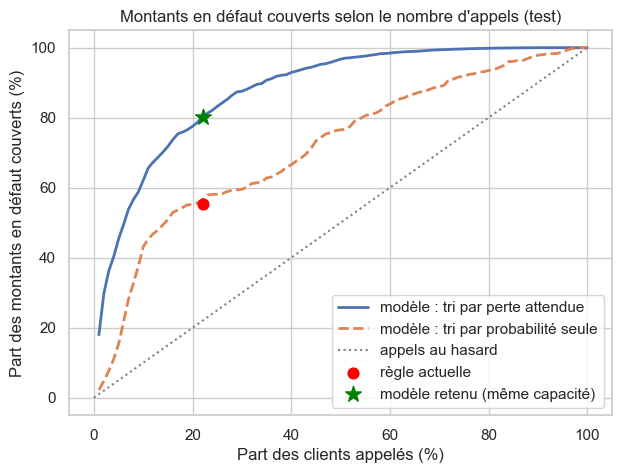

In [6]:
parts = np.linspace(0.01, 1, 100)

def montants_couverts(score):
    resultat = []
    for part in parts:
        appele = appeler_les_plus_risques(score, part)
        resultat.append(montant_test[appele & defaut_test].sum() / montant_test[defaut_test].sum() * 100)
    return resultat

retenu = comparaison.loc["Modèle, même capacité (retenu)"]
# part des montants en défaut couverts selon le nombre de clients appelés

plt.figure(figsize=(7, 5))

plt.plot(parts * 100, montants_couverts(perte_attendue_test), lw=2, label="modèle : tri par perte attendue")

plt.plot(parts * 100, montants_couverts(proba_test), lw=2, linestyle="--", label="modèle : tri par probabilité seule")

plt.plot([0, 100], [0, 100], ":", color="gray", label="appels au hasard")

plt.scatter([comparaison.loc["Règle actuelle", "clients appelés (%)"]],
            [comparaison.loc["Règle actuelle", "montants en défaut couverts (%)"]],
            color="red", s=60, zorder=3, label="règle actuelle")

plt.scatter([retenu["clients appelés (%)"]], [retenu["montants en défaut couverts (%)"]],
            color="green", marker="*", s=140, zorder=3, label="modèle retenu (même capacité)")

plt.xlabel("Part des clients appelés (%)")

plt.ylabel("Part des montants en défaut couverts (%)")

plt.title("Montants en défaut couverts selon le nombre d'appels (test)")

plt.legend(loc="lower right")

plt.savefig(FIGURES + "couverture montant.png", dpi=150, bbox_inches="tight")

plt.show()

La courbe du modèle trié par perte attendue est nettement au-dessus de la règle et du tri par probabilité seule : à nombre d'appels égal, elle couvre beaucoup plus de montants. Trier par probabilité seule ferait à peine mieux que la règle. C'est la prise en compte du montant qui fait la différence.

## 5. ROI (axe 7)

Formules (consignes) :
- gain annuel = coût avec la règle actuelle − coût avec le modèle (sur le test, puis × 5 × 12) ;
- ROI (%) = (gain annuel − coût du projet) / coût du projet × 100 ;
- délai de retour (mois) = coût du projet / (gain annuel / 12).

Politique retenue : **même nombre d'appels qu'aujourd'hui, en commençant par les plus fortes pertes attendues**. Comme le nombre d'appels ne change pas, tout le gain vient du meilleur ciblage.

In [7]:
appele_modele = politiques["Modèle, même capacité (retenu)"]

gain_mois = comparaison.loc["Modèle, même capacité (retenu)", "gain vs règle (€)"]

gain_annuel = gain_mois * FACTEUR_ANNUEL

roi = (gain_annuel - COUT_PROJET) / COUT_PROJET * 100

retour = COUT_PROJET / (gain_annuel / 12)

# ROI : gain annuel (x 5 x 12), ROI de la 1re année et délai de retour

print("Gain sur le test (1 mois) :", round(gain_mois), "€")

print("Gain annuel               :", round(gain_annuel), "€")

print("Coût du projet            :", COUT_PROJET, "€")

print("ROI 1re année             :", round(roi), "%")

print("Délai de retour           :", round(retour, 1), "mois")

Gain sur le test (1 mois) : 4202 €
Gain annuel               : 252122 €
Coût du projet            : 55000 €
ROI 1re année             : 358 %
Délai de retour           : 2.6 mois


### Incertitude liée au test

Le gain dépend des 6 000 clients du test. Pour mesurer cette incertitude, je fais un bootstrap : je tire 2 000 fois 6 000 clients au hasard (avec remise) et je recalcule le gain à chaque fois. Les décisions d'appel restent celles du modèle et de la règle.

In [8]:
rng = np.random.default_rng(42)

gains = []

for _ in range(2000):
    i = rng.integers(0, len(defaut_test), len(defaut_test))     
    # tirage avec remise
    gain = (cout_total(regle_test[i], defaut_test[i], montant_test[i])
            - cout_total(appele_modele[i], defaut_test[i], montant_test[i]))
    gains.append(gain * FACTEUR_ANNUEL)

bas, haut = np.percentile(gains, [5, 95])

# le bootstrap : 2 000 tirages du test pour mesurer l'incertitude du gain

print("Gain annuel :", round(gain_annuel), "€ | intervalle à 90 % :", round(bas), "à", round(haut), "€")

print("Part des tirages où le gain dépasse le coût du projet :", round(np.mean(np.array(gains) > COUT_PROJET) * 100), "%")

Gain annuel : 252122 € | intervalle à 90 % : 196742 à 308582 €
Part des tirages où le gain dépasse le coût du projet : 100 %


### Sensibilité aux hypothèses

La politique est fixée. Je change les hypothèses pour voir ce que devient le gain. Le coût d'un appel ne joue pas ici : le modèle et la règle font le même nombre d'appels.

In [9]:
# Sensibilité : le gain selon les hypothèses de perte et d'efficacité
scenarios = [

# (nom, perte, efficacité, facteur annuel)
    ("Central (perte 10 %, efficacité 10 %)", 0.10, 0.10, FACTEUR_ANNUEL),
    ("Pessimiste (perte 5 %, efficacité 5 %)", 0.05, 0.05, FACTEUR_ANNUEL),
    ("Optimiste (perte 15 %, efficacité 20 %)", 0.15, 0.20, FACTEUR_ANNUEL),
    ("Gain sur 6 mois seulement", 0.10, 0.10, 5 * 6),
]

lignes = []

for nom, perte, efficacite, facteur in scenarios:
    gain = (cout_total(regle_test, defaut_test, montant_test, perte, efficacite)
            - cout_total(appele_modele, defaut_test, montant_test, perte, efficacite)) * facteur
    lignes.append({"scénario": nom,
                   "gain annuel (€)": round(gain),
                   "ROI 1re année (%)": round((gain - COUT_PROJET) / COUT_PROJET * 100),
                   "retour (mois)": round(COUT_PROJET / (gain / 12), 1)})

# Efficacité minimale pour rembourser le projet : je l'augmente de 0,1 point jusqu'à ce que le gain suffise

for efficacite in np.arange(0, 0.301, 0.001):
    gain = (cout_total(regle_test, defaut_test, montant_test, PERTE, efficacite)
            - cout_total(appele_modele, defaut_test, montant_test, PERTE, efficacite)) * FACTEUR_ANNUEL
    if gain >= COUT_PROJET:
        break

efficacite_min = efficacite

print("Efficacité minimale pour rembourser le projet :", round(efficacite_min * 100, 1), "%")

pd.DataFrame(lignes).set_index("scénario")

Efficacité minimale pour rembourser le projet : 2.2 %


,gain annuel (€),ROI 1re année (%),retour (mois)
scénario,,,
"Central (perte 10 %, efficacité 10 %)",252122,358,2.6
"Pessimiste (perte 5 %, efficacité 5 %)",63030,15,10.5
"Optimiste (perte 15 %, efficacité 20 %)",756365,1275,0.9
Gain sur 6 mois seulement,126061,129,5.2


- Gain central : environ 252 000 € par an pour un coût de 55 000 €, soit un ROI de 358 % et un retour en 2,6 mois.
- Le bootstrap donne un gain entre 197 000 € et 309 000 € dans 90 % des tirages : le résultat ne vient pas d'un hasard du jeu de test.
- Le gain dépend surtout des hypothèses de perte et d'efficacité. Dans le scénario pessimiste (5 % de perte, 5 % d'efficacité, soit le niveau d'un simple SMS), il tombe à 63 000 € : le projet reste juste rentable (ROI de 15 %).
- Le projet est remboursé dès que l'appel évite 2,2 % des pertes, alors que même un simple rappel en évite 4 à 7 % dans les études. L'efficacité réelle d'un appel reste l'hypothèse la plus importante : elle doit être mesurée par un pilote, avec un groupe de clients non appelés pour comparer.
- Le gain s'explique par les montants en jeu (environ 1,7 M€ de factures partent en défaut chaque mois rien que sur les 6 000 clients du test) et par le fait que le modèle n'ajoute aucun appel. Il reste une estimation, pas une certitude.
- Pour le scénario « gain sur 6 mois seulement », le délai de retour dépend du moment où tombent ces 6 mois de gain : 2,6 mois s'ils arrivent dès le début, 5,2 mois (tableau) si le gain est réparti sur l'année. Je ne donne donc pas de chiffre dans le rapport (« – »).

## 6. Équité (axe 9)

Le modèle n'utilise ni le sexe, ni l'âge, ni la situation familiale. Mais il pourrait les retrouver indirectement à travers d'autres variables. Je regarde, pour chaque groupe du test : la part de clients appelés, le taux de défaut réel, et la part des défauts trouvés.

Ici, être appelé n'est pas une sanction : c'est un rappel ou une proposition d'aide. Le risque principal serait qu'un groupe soit moins aidé que les autres à risque égal.

In [10]:
infos = df.loc[X_test.index]

appele = pd.Series(appele_modele, index=X_test.index)

trouve = pd.Series(appele_modele & defaut_test, index=X_test.index)

def par_groupe(groupes):
    return pd.DataFrame({
        "clients": groupes.value_counts(),
        "appelés (%)": appele.groupby(groupes, observed=True).mean() * 100,
        "taux de défaut (%)": y_test.groupby(groupes, observed=True).mean() * 100,
        "défauts trouvés (%)": trouve.groupby(groupes, observed=True).sum() / y_test.groupby(groupes, observed=True).sum() * 100,
    }).round(1)

sexe = infos["sexe"].map({1: "Homme", 2: "Femme"})

age = pd.cut(infos["age"], [20, 25, 35, 45, 55, 80], labels=["21-25", "26-35", "36-45", "46-55", "56 et +"])

situation = infos["statut_marital"].map({1: "Marié", 2: "Célibataire", 3: "Autre"})

# equité : qui est appelé selon le sexe, l'âge et la situation familiale

print(par_groupe(sexe), "\n")

print(par_groupe(age), "\n")

print(par_groupe(situation))

print("\nFacture de septembre médiane (TWD) par âge :")

print(infos.groupby(age, observed=True)["facture_sep"].median())

       clients  appelés (%)  taux de défaut (%)  défauts trouvés (%)
sexe                                                                
Femme     3598         21.8                21.3                 37.9
Homme     2402         22.5                23.4                 34.4 

         clients  appelés (%)  taux de défaut (%)  défauts trouvés (%)
age                                                                   
21-25        767         20.3                25.6                 34.7
26-35       2492         22.4                19.7                 36.7
36-45       1775         22.6                22.4                 38.5
46-55        788         21.4                25.1                 33.8
56 et +      178         22.5                25.8                 32.6 

                clients  appelés (%)  taux de défaut (%)  défauts trouvés (%)
statut_marital                                                               
Autre                75         16.0                16.0           

- Sexe : 21,8 % des femmes et 22,5 % des hommes sont appelés, pour des taux de défaut de 21,3 % et 23,4 %. La part des défauts trouvés est proche (38 % et 34 %).
- Âge : les 21-25 ans sont un peu moins appelés (20,3 %) alors que leur taux de défaut est parmi les plus élevés (25,6 %). Leurs factures sont plus petites (médiane d'environ 19 500 TWD, contre 22 000 à 25 000 TWD pour les 26-45 ans et les 56 ans et plus), donc leur perte attendue aussi. Les 46-55 ans sont dans le même cas (médiane d'environ 19 700 TWD, 21,4 % appelés pour 25,1 % de défauts). C'est un effet du tri par montant, pas de l'âge lui-même, mais il faut le suivre (registre des risques).
- Situation familiale : écarts faibles. Le groupe « autre » est trop petit (75 clients) pour conclure.

Je ne vois pas d'écart majeur, mais un suivi par groupe reste nécessaire après le déploiement.

## 7. Registre des risques (axe 9)

| Risque | Probabilité | Impact | Mesure |
|---|---|---|---|
| L'appel est moins efficace que prévu (10 %) | moyenne | élevé | Pilote de 3 mois avec un groupe témoin non appelé, pour mesurer l'efficacité réelle. Le projet reste rentable à partir d'une efficacité très faible (partie 5). |
| Les clients d'aujourd'hui ne se comportent pas comme ceux de Taïwan en 2005 (dérive) | élevée | élevé | Réentraîner le modèle sur les données récentes de la banque avant tout déploiement, puis suivre chaque mois l'AUC et les montants couverts. |
| Les défauts de clients sans aucun retard passé restent invisibles | certaine | moyen | Limite connue (notebook 02). Ajouter d'autres données (revenus, autres crédits) dans une version suivante. |
| Les petits montants sont moins appelés, car on trie par perte attendue | élevée | moyen | Suivre les taux d'appel par groupe ; si besoin, réserver une partie des appels aux clients à forte probabilité mais petit montant. |
| Sur-apprentissage ou fuite de données | faible | élevé | Split avant toute préparation, préparation dans le `Pipeline`, test utilisé une seule fois ; écart entre train et validation surveillé (0,835 contre 0,786). |
| Déséquilibre des classes (22 % de défauts) | certaine | moyen | Split stratifié ; métriques adaptées (ROC-AUC, rappel, montants couverts) au lieu de l'accuracy. |
| Cible mal définie (le mois exact du défaut n'est pas documenté) | faible | moyen | Vérifier la définition du défaut avec la banque avant le pilote. |
| Discrimination indirecte (sexe, âge, situation familiale) | faible | élevé | Variables protégées exclues du modèle ; contrôle par groupe (partie 6) refait à chaque réentraînement. |
| Données personnelles (RGPD) | moyenne | élevé | Pas d'identité dans le modèle, accès limité aux scores, information des clients. Le conseiller garde la décision d'appeler : ce n'est pas une décision automatique. |
| Les conseillers n'utilisent pas l'outil | moyenne | moyen | Même nombre d'appels qu'aujourd'hui, et un motif clair pour chaque appel (retards, plafond presque atteint, gros montant). |
| Coût environnemental | faible | faible | Modèle léger : quelques minutes d'entraînement sur un ordinateur portable (recherche des réglages comprise), réentraînement mensuel au plus. |

## 8. Recommandation

In [11]:
retenu = comparaison.loc["Modèle, même capacité (retenu)"]
regle = comparaison.loc["Règle actuelle"]
seuil_rentable = comparaison.loc["Modèle, seuil 1 000 € (rentabilité)"]
#le résumé des résultats pour la recommandation
print("RÉSUMÉ")
print("- Garder le même nombre d'appels, mais appeler en priorité les plus fortes pertes attendues.")
print("- Sur le test, avec", round(retenu["clients appelés (%)"]), "% de clients appelés :",
      round(retenu["montants en défaut couverts (%)"], 1), "% des montants en défaut couverts, contre",
      round(regle["montants en défaut couverts (%)"], 1), "% avec la règle actuelle.")
print("- Gain estimé :", round(gain_annuel), "€ par an (intervalle à 90 % :", round(bas), "à", round(haut),
      "€), pour un coût de", COUT_PROJET, "€. Retour en", round(retour, 1), "mois.")
print("- Hypothèse critique : l'efficacité des appels. Le projet est rentable dès", round(efficacite_min * 100, 1), "%.")
print("- Piste : appeler seulement si la perte attendue dépasse", round(SEUIL), "€ (",
      round(seuil_rentable["clients appelés (%)"]), "% des clients,", round(seuil_rentable["montants en défaut couverts (%)"]),
      "% des montants couverts ).")


RÉSUMÉ
- Garder le même nombre d'appels, mais appeler en priorité les plus fortes pertes attendues.
- Sur le test, avec 22 % de clients appelés : 80.3 % des montants en défaut couverts, contre 55.3 % avec la règle actuelle.
- Gain estimé : 252122 € par an (intervalle à 90 % : 196742 à 308582 €), pour un coût de 55000 €. Retour en 2.6 mois.
- Hypothèse critique : l'efficacité des appels. Le projet est rentable dès 2.2 %.
- Piste : appeler seulement si la perte attendue dépasse 1000 € ( 7 % des clients, 54 % des montants couverts ).


## Résumé

- Décision : garder le même nombre d'appels, mais appeler en priorité les clients dont la perte attendue (probabilité × montant) est la plus forte.
- Sur le test : 80,3 % des montants en défaut couverts, contre 55,3 % avec la règle actuelle. Le critère de succès est atteint.
- Gain estimé : environ 252 000 € par an (entre 197 000 et 309 000 €), pour un coût de 55 000 €. ROI de 358 %, retour en 2,6 mois. Les hypothèses de coût s'appuient sur des études publiques.
- Hypothèse critique : l'efficacité des appels. Le projet est rentable dès 2,2 %.
- Recommandation : un pilote de 3 mois sur une partie des clients, avec un groupe témoin, pour mesurer l'efficacité réelle avant de généraliser.
- Piste : avec nos hypothèses, appeler seulement 7 % des clients (perte attendue > 1 000 €) couvrirait presque autant de montants que la règle actuelle, avec trois fois moins d'appels.